# Trajectory Inference via Mean-Field Langevin in Path Space
### An interactive, from-scratch guide to Chizat, Zhang, Heitz & Schiebinger (NeurIPS 2022)

> L. Chizat\*, S. Zhang\*, M. Heitz, G. Schiebinger. *Trajectory Inference via Mean-field Langevin in Path Space.* NeurIPS 2022. [arXiv:2205.07146](https://arxiv.org/abs/2205.07146)

This notebook is a self-contained companion to the paper. It

1. **formally introduces trajectory inference**: what the problem is and why it is ill-posed without a prior,
2. **derives the min-entropy estimator** and its reduction to a family of coupled Schrödinger bridges,
3. **implements the Mean-Field Langevin (MFL) algorithm from scratch** in plain NumPy (log-domain Sinkhorn, data-fitting forces, noisy particle updates),
4. **reproduces the paper's main experiments**: the bifurcating process (Fig. 1–2), robustness to few samples (Fig. 1), branching/growth (Fig. 3) and simulated annealing (App. F).

Everything runs on a laptop CPU. The only dependencies are `numpy`, `scipy`, `matplotlib` and (optionally) `ipywidgets`.

---

**Contents**

1. [The trajectory inference problem](#1)
2. [A model for population dynamics](#2)
3. [The min-entropy estimator in path space](#3)
4. [Reduction to coupled Schrödinger bridges](#4)
5. [Mean-Field Langevin dynamics](#5)
6. [Experiment: reconstructing a bifurcation](#6)
7. [From marginals back to trajectories](#7)
8. [Grid-free inference: robustness to few samples](#8)
9. [Dealing with branching (cell division and death)](#9)
10. [Simulated annealing](#10)
11. [Interactive playground](#11)
12. [Summary and references](#12)

In [1]:
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import animation
from scipy.spatial import cKDTree
from scipy.special import digamma, gammaln

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold",
})
TIME_CMAP = "viridis"
ASSETS = Path("assets"); ASSETS.mkdir(exist_ok=True)
rng = np.random.default_rng(0)

<a id="1"></a>
## 1. The trajectory inference problem

Many systems in biology are observed through **destructive measurements**. In single-cell RNA sequencing, for instance, measuring a cell's state means lysing it: we see a snapshot of the *population* at time $t_i$, but we never follow any individual cell over time. Trajectory inference asks:

> *Given snapshots of a population at a few time points, recover how individuals moved between them.*

**Formal setup.** Let $\mathcal X\subset\mathbb R^d$ be the state space and $\Omega = \mathcal C([0,1];\mathcal X)$ the space of continuous paths. The population evolves according to an unknown stochastic process $(X_t)_{t\in[0,1]}$ with law $P\in\mathcal P(\Omega)$, a probability measure *on paths*. At times $0\le t_1<\dots<t_T\le 1$ we observe i.i.d. samples, **each from a different individual**, which we summarise as empirical measures

$$
\hat\mu_{t_i} = \frac{1}{n_i}\sum_{j=1}^{n_i}\delta_{X_{t_i,j}}\in\mathcal P(\mathcal X),\qquad i=1,\dots,T .
$$

The goal is to estimate $P$ from $(\hat\mu_{t_1},\dots,\hat\mu_{t_T})$. Note that $P$ contains far more information than its marginals $P_t=(e_t)_\#P$ (where $e_t:\omega\mapsto\omega(t)$): it also encodes the **couplings** $P_{t_i,t_j}$, i.e. *which* cells at time $t_i$ become *which* cells at time $t_j$.

### Why the problem is ill-posed

Marginals alone never determine the law of a process. The cell below shows two processes with **exactly the same marginal $\mathcal N(0,1)$ at every time**:

* **(a)** each particle stays where it is, $X_t\equiv X_0$;
* **(b)** a stationary Ornstein–Uhlenbeck process, $\mathrm dX_t = -X_t\,\mathrm dt + \sqrt 2\,\mathrm dB_t$.

Any snapshot-based method sees identical data, yet the dynamics are completely different. Some prior on the dynamics is unavoidable, and the paper's choice of prior is the subject of Section 3.

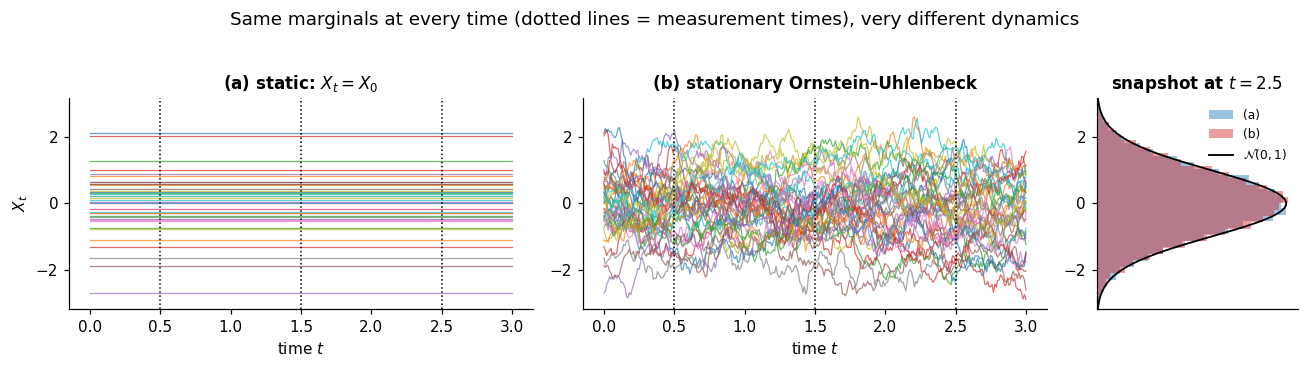

In [2]:
def ou_paths(n, ts, theta=1.0, rng=None):
    rng = np.random.default_rng(rng)
    X = np.empty((len(ts), n)); X[0] = rng.standard_normal(n)
    for k in range(1, len(ts)):
        h = ts[k] - ts[k - 1]; a = np.exp(-theta * h)
        X[k] = a * X[k - 1] + np.sqrt(1 - a ** 2) * rng.standard_normal(n)
    return X

tt = np.linspace(0, 3, 300)
static = np.repeat(np.random.default_rng(1).standard_normal((1, 40)), len(tt), 0)
ou = ou_paths(40, tt, rng=1)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), gridspec_kw=dict(width_ratios=[3, 3, 1.3]))
for ax, P, title in [(axes[0], static, "(a) static: $X_t = X_0$"),
                     (axes[1], ou, "(b) stationary Ornstein–Uhlenbeck")]:
    ax.plot(tt, P, lw=0.8, alpha=0.7)
    for ts_ in [0.5, 1.5, 2.5]:
        ax.axvline(ts_, color="k", ls=":", lw=1)
    ax.set(title=title, xlabel="time $t$", ylim=(-3.2, 3.2))
axes[0].set_ylabel("$X_t$")
grid = np.linspace(-3.2, 3.2, 200)
big = np.random.default_rng(2).standard_normal(20000)
for P, c, lab in [(big, "C0", "(a)"), (ou_paths(20000, [0, 2.5], rng=3)[-1], "C3", "(b)")]:
    axes[2].hist(P, bins=40, density=True, orientation="horizontal", alpha=0.45, color=c, label=lab)
axes[2].plot(np.exp(-grid ** 2 / 2) / np.sqrt(2 * np.pi), grid, "k", lw=1.2, label="$\\mathcal{N}(0,1)$")
axes[2].set(title="snapshot at $t=2.5$", xticks=[], ylim=(-3.2, 3.2)); axes[2].legend(fontsize=8, frameon=False)
fig.suptitle("Same marginals at every time (dotted lines = measurement times), very different dynamics", y=1.03)
plt.tight_layout(); plt.show()

<a id="2"></a>
## 2. A model for population dynamics

Following the paper (and Waddington's *epigenetic landscape* picture of cell differentiation), we take as a model of the ground truth a **drift-diffusion process**

$$
\mathrm dX_t = -\nabla\Psi(t,X_t)\,\mathrm dt + \sqrt{\tau}\,\mathrm dB_t,\qquad \mathrm{Law}(X_0)=\mu_0, \tag{1}
$$

where $\Psi$ is an unknown time-dependent potential (the *Waddington landscape*), $B$ is a Brownian motion and $\tau>0$ is a known diffusivity. Only the gradient part of the drift is identifiable from marginals, which is why the drift is written as $-\nabla\Psi$.

**Test system (paper, Sec. 4.1 / App. G.1).** In $\mathcal X=\mathbb R^{10}$, with $\tau = 1/4$,

$$
\Psi(t,x) = \tfrac12 (x_1-1.5)^2(x_1+1.5)^2 + 10\,(x_2+t)^2 + 10\sum_{k=3}^{10}x_k^2 ,\qquad X_0\sim\mathcal N(0,0.1^2 I).
$$

The first coordinate has a double well, so the population **bifurcates** into two branches. The second coordinate is dragged downwards over time. The remaining 8 coordinates are pure noise confined near 0, which makes the problem genuinely 10-dimensional. We observe $T=10$ evenly spaced snapshots on $[0,1.25]$.

In [3]:
TAU = 0.25                        # diffusivity of the ground-truth process (assumed known)
D = 10                            # ambient dimension
TS = np.linspace(0, 1.25, 10)     # measurement times t_1..t_T

def drift_bifurcation(t, X):
    # grad Psi(t, x) for the bifurcating potential
    g = np.empty_like(X)
    g[:, 0] = 2 * X[:, 0] * (X[:, 0] ** 2 - 2.25)
    g[:, 1] = 20 * (X[:, 1] + t)
    g[:, 2:] = 20 * X[:, 2:]
    return g

def simulate(n, ts, drift, tau, d=D, dt=1e-3, x0_scale=0.1, rng=None, return_paths=False):
    # Euler–Maruyama for dX = -drift dt + sqrt(tau) dB; returns X at the times ts, shape (T, n, d)
    rng = np.random.default_rng(rng)
    X = x0_scale * rng.standard_normal((n, d))
    steps = np.round(np.asarray(ts) / dt).astype(int)
    snaps, path = [], []
    for k in range(steps[-1] + 1):
        if k in steps:
            snaps.append(X.copy())
        if return_paths and k % 10 == 0:
            path.append(X.copy())
        X = X - drift(k * dt, X) * dt + np.sqrt(tau * dt) * rng.standard_normal(X.shape)
    snaps = np.stack(snaps)
    return (snaps, np.stack(path)) if return_paths else snaps

def make_snapshots(ns, ts, drift, tau, rng=None, **kw):
    # independent samples: every observed particle comes from a different trajectory
    pool = simulate(sum(ns), ts, drift, tau, rng=rng, **kw)
    offs = np.cumsum([0] + list(ns))
    return [pool[i, offs[i]:offs[i + 1]] for i in range(len(ts))]

# observed data (N = 64 samples per time point) and a large "ground truth" reference
obs64 = make_snapshots([64] * 10, TS, drift_bifurcation, TAU, rng=1)
truth = simulate(500, TS, drift_bifurcation, TAU, rng=2)
_, gt_paths = simulate(150, TS, drift_bifurcation, TAU, rng=3, return_paths=True)
print("snapshots:", [o.shape for o in obs64][:3], "...")

snapshots: [(64, 10), (64, 10), (64, 10)] ...


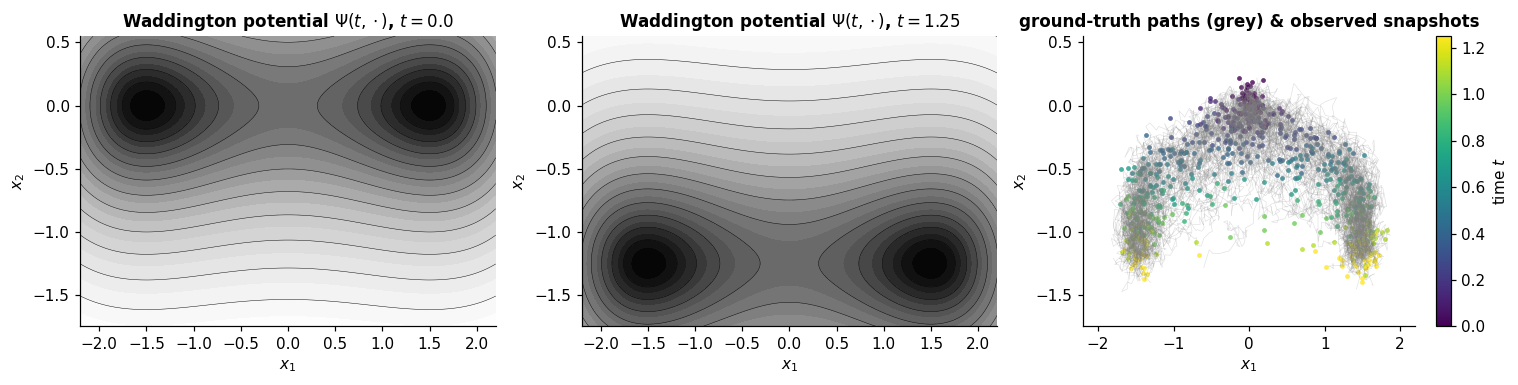

In [4]:
def scatter_snapshots(ax, snaps, ts, s=10, alpha=0.8, **kw):
    norm = mpl.colors.Normalize(ts.min(), ts.max())
    for x, t in zip(snaps, ts):
        ax.scatter(x[:, 0], x[:, 1], s=s, color=plt.get_cmap(TIME_CMAP)(norm(t)), alpha=alpha, lw=0, **kw)
    return mpl.cm.ScalarMappable(norm=norm, cmap=TIME_CMAP)

def style_xy(ax, title=None):
    ax.set(xlim=(-2.2, 2.2), ylim=(-1.75, 0.55), xlabel="$x_1$", ylabel="$x_2$", title=title)

x1, x2 = np.meshgrid(np.linspace(-2.2, 2.2, 200), np.linspace(-1.75, 0.55, 200))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, t in zip(axes[:2], [0.0, 1.25]):
    Psi = 0.5 * (x1 - 1.5) ** 2 * (x1 + 1.5) ** 2 + 10 * (x2 + t) ** 2
    cs = ax.contourf(x1, x2, np.log1p(Psi), levels=25, cmap="Greys_r")
    ax.contour(x1, x2, np.log1p(Psi), levels=12, colors="k", linewidths=0.3)
    style_xy(ax, f"Waddington potential $\\Psi(t,\\cdot)$, $t={t}$")
axes[2].plot(gt_paths[:, :, 0], gt_paths[:, :, 1], color="grey", lw=0.4, alpha=0.25)
sm = scatter_snapshots(axes[2], obs64, TS)
style_xy(axes[2], "ground-truth paths (grey) & observed snapshots")
fig.colorbar(sm, ax=axes[2], label="time $t$")
plt.tight_layout(); plt.show()

In the right panel the grey trajectories are **hidden** from us. The algorithm only sees the coloured points, and points of different colours belong to different individuals.

<a id="3"></a>
## 3. The min-entropy estimator in path space

Lavenant et al. (2021) proposed to regularise trajectory inference with the **relative entropy with respect to Brownian motion**. Let $W^\tau\in\mathcal P(\Omega)$ be the law of (reflected) Brownian motion with diffusivity $\tau$. The estimator is the unique minimiser $R^\star$ of

$$
\mathcal F(R) \;=\; \frac1\lambda\sum_{i=1}^T \Delta t_i\,\mathrm{Fit}_\sigma\big(R_{t_i}\,\big|\,\hat\mu_{t_i}\big) \;+\; \tau\, H(R\,|\,W^\tau), \qquad R\in\mathcal P(\Omega). \tag{2}
$$

* $H(R\,|\,W^\tau)=\int\log\frac{\mathrm dR}{\mathrm dW^\tau}\,\mathrm dR$ favours path laws that look as **Brownian as possible**. Among all processes compatible with the data, it selects the one requiring the "least surprising" deviation from pure diffusion. This is the classical *Schrödinger problem*: drift-diffusions of the form (1) are, locally, exactly the processes this prior is designed for.
* $\lambda>0$ trades data fidelity for regularity, and $\Delta t_i = (t_{i+1}-t_{i-1})/2$ are quadrature weights.
* **Consistency (Thm. 2.1, from Lavenant et al.).** As the time points become dense and then $\lambda,\sigma\to0$, $R^\star\to P$, so the estimator recovers the true law on paths.

### The data-fitting term

The paper uses a log-likelihood under a Gaussian noise model $\hat X = X + \sigma Z$:

$$
\mathrm{Fit}_\sigma(R_t\,|\,\hat\mu_t) = -\int \log\Big[\int \exp\Big(-\frac{\|x-y\|^2}{2\sigma^2}\Big)\,\mathrm dR_t(x)\Big]\,\mathrm d\hat\mu_t(y). \tag{3}
$$

This is a **soft-min**. Each observation $y$ pulls on the reconstructed particles $x$ with weight proportional to $e^{-\|x-y\|^2/2\sigma^2}$, normalised over all particles. As a result, the particles *closest* to an observation are attracted to it, even if they are far away in absolute terms, while distant particles are barely affected. The term is convex in $R_t$, and when $R_t=\frac1m\sum_k\delta_{x_k}$ its gradient with respect to particle $x_k$ (times $m$) is

$$
m\,\nabla_{x_k}\mathrm{Fit}_\sigma = \frac{1}{\sigma^2}\sum_{j} \hat w_j\,\frac{g_\sigma(x_k-y_j)}{\frac1m\sum_{l}g_\sigma(x_l-y_j)}\,(x_k-y_j).
$$

The figure below visualises this force field: the arrows show $-\nabla$Fit acting on a cloud of particles, given a handful of observations.

In [5]:
def lse(a, axis, keepdims=False):
    # numerically stable log-sum-exp (faster than scipy's for our small batched arrays)
    m = a.max(axis=axis, keepdims=True)
    out = np.log(np.exp(a - m).sum(axis=axis, keepdims=True)) + m
    return out if keepdims else np.squeeze(out, axis)

def sqdist(x, y):
    # cost c(x, y) = ||x - y||^2 / 2 for (batched) point clouds x (..., m, d), y (..., n, d)
    xx = (x ** 2).sum(-1)[..., :, None]
    yy = (y ** 2).sum(-1)[..., None, :]
    return 0.5 * np.maximum(xx + yy - 2 * x @ np.swapaxes(y, -1, -2), 0.0)

def fit_terms(X, Y, sigma):
    # value of Fit_sigma(mu_X | mu_hat_Y) (up to a constant) and m * gradient w.r.t. the particles X
    m, n = len(X), len(Y)
    K = -sqdist(X, Y) / sigma ** 2 - np.log(m)   # log[ g_sigma(x_k - y_j) / m ]
    logZ = lse(K, 0, keepdims=True)              # log (g_sigma * mu)(y_j)
    W = np.exp(K - logZ) * m / n                 # g(x_k - y_j) / Z_j * w_j
    grad = (W.sum(1)[:, None] * X - W @ Y) / sigma ** 2
    return -logZ.mean(), grad

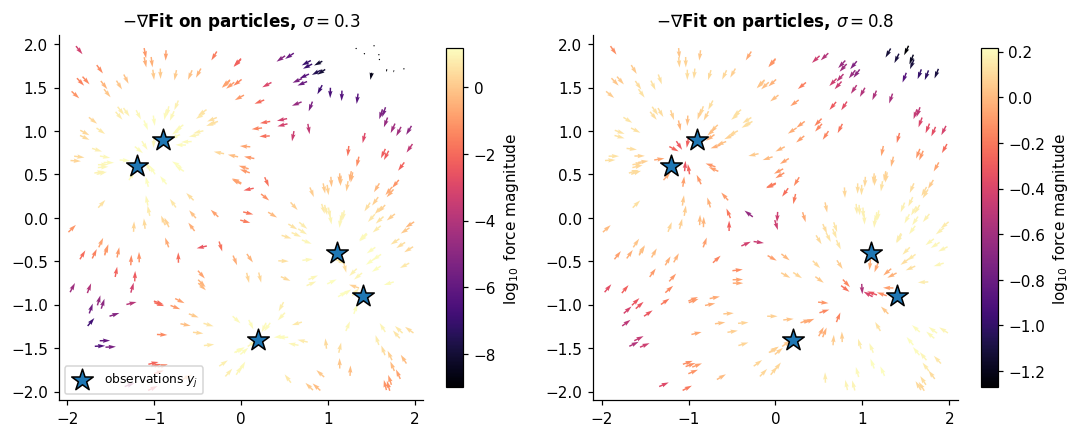

In [6]:
r = np.random.default_rng(4)
Y_demo = np.array([[-1.2, 0.6], [-0.9, 0.9], [1.1, -0.4], [1.4, -0.9], [0.2, -1.4]])
X_demo = r.uniform(-2, 2, size=(300, 2))
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, s in zip(axes, [0.3, 0.8]):
    _, g = fit_terms(X_demo, Y_demo, s)
    mag = np.linalg.norm(g, axis=1)
    q = ax.quiver(X_demo[:, 0], X_demo[:, 1], -g[:, 0] / (mag + 1e-9), -g[:, 1] / (mag + 1e-9),
                  np.log10(mag + 1e-9), cmap="magma", scale=35, width=0.004)
    ax.scatter(*Y_demo.T, marker="*", s=220, c="C0", edgecolor="k", zorder=3, label="observations $y_j$")
    ax.set(title=f"$-\\nabla$Fit on particles, $\\sigma={s}$", aspect="equal", xlim=(-2.1, 2.1), ylim=(-2.1, 2.1))
    fig.colorbar(q, ax=ax, label="$\\log_{10}$ force magnitude", shrink=0.8)
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

Each particle is pulled towards the observation it is (softly) "assigned" to. A smaller $\sigma$ gives sharper assignments and stronger, more local forces.

<a id="4"></a>
## 4. Reduction to coupled Schrödinger bridges

Problem (2) is posed over measures on an **infinite-dimensional** path space. The paper's first key step is to reduce it to an optimisation over $T$ measures on $\mathcal X$.

### Entropic optimal transport (static Schrödinger bridge)

For $\mu,\nu\in\mathcal P(\mathcal X)$ and $\tau_i>0$ define

$$
T_{\tau_i}(\mu,\nu)=\min_{\gamma\in\Pi(\mu,\nu)} \int c_{\tau_i}(x,y)\,\mathrm d\gamma(x,y)+\tau_i\,H(\gamma\,|\,\mu\otimes\nu), \tag{6}
$$

where $c_{\tau_i}=-\tau_i\log p_{\tau_i}$ and $p$ is the heat kernel. On $\mathbb R^d$ this is exactly $c(x,y)=\tfrac12\|x-y\|^2$ up to a constant (Varadhan's formula), which is what we use. $T_{\tau_i}$ is the cost of the **most likely way for a Brownian cloud to travel from $\mu$ to $\nu$**.

It has a dual formulation with **Schrödinger potentials** $(\varphi,\psi)$ satisfying (App. A, Eq. 16)

$$
\varphi(x) = -\tau_i\log\!\int e^{(\psi(y)-c(x,y))/\tau_i}\,\mathrm d\nu(y),\qquad
\psi(y) = -\tau_i\log\!\int e^{(\varphi(x)-c(x,y))/\tau_i}\,\mathrm d\mu(x),
$$

and the optimal plan is $\mathrm d\gamma^\star = e^{(\varphi\oplus\psi-c)/\tau_i}\,\mathrm d(\mu\otimes\nu)$. Iterating these two equations is **Sinkhorn's algorithm**. A property that matters below (Eq. 18) is

$$
\nabla\varphi(x) = \mathbb E_{\gamma^\star}\big[\nabla_x c(X,Y)\,\big|\,X=x\big] = x-\mathbb E_{\gamma^\star}[Y\,|\,X=x],
$$

so the gradient of the potential points from $x$ towards the **barycentre of where $x$ is sent**.

In [7]:
def sinkhorn(C, logp, logq, eps, u=None, v=None, n_iter=1000, tol=1e-4):
    # Batched log-domain Sinkhorn for B entropic OT problems at once.
    # C: (B, m, n) costs, logp: (B, m), logq: (B, n) log-weights, eps: (B,) regularisations.
    # Returns the Schrödinger potentials u = phi(x_i), v = psi(y_j). (u, v) can be warm-started.
    e = eps[:, None, None]
    u = np.zeros(logp.shape) if u is None else u
    v = np.zeros(logq.shape) if v is None else v
    for it in range(1, n_iter + 1):
        u = -eps[:, None] * lse((v[:, None, :] - C) / e + logq[:, None, :], 2)
        v = -eps[:, None] * lse((u[:, :, None] - C) / e + logp[:, :, None], 1)
        if tol is not None and it % 10 == 0:
            row = lse((u[:, :, None] + v[:, None, :] - C) / e + logq[:, None, :], 2)
            if np.abs(np.expm1(row)).max() < tol:   # row marginals of the plan match p
                break
    return u, v

def conditional_weights(C, pot, logw, eps, axis):
    # Conditional laws of the optimal plan (rows/columns of gamma, normalised):
    #   axis=2: W[b, i, j] = gamma(y_j | x_i), uses (v, log q)
    #   axis=1: W[b, i, j] = gamma(x_i | y_j), uses (u, log p)
    e = eps[:, None, None]
    A = (pot[:, None, :] - C) / e + logw[:, None, :] if axis == 2 else (pot[:, :, None] - C) / e + logw[:, :, None]
    return np.exp(A - lse(A, axis, keepdims=True))

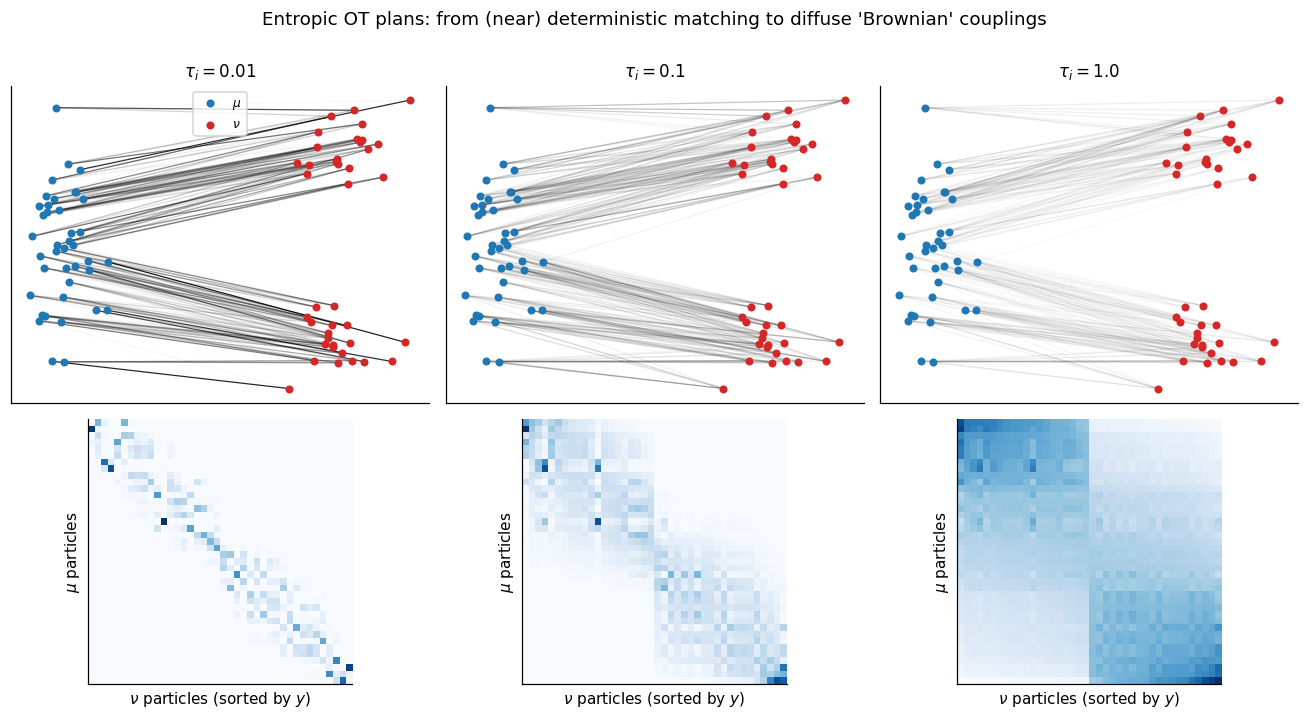

In [8]:
# Schrödinger bridges between two clouds for increasing temperature
r = np.random.default_rng(5)
mu = np.c_[r.normal(-1.5, 0.25, 40), r.normal(0, 0.6, 40)]
nu = np.c_[r.normal(1.5, 0.35, 40), np.where(r.random(40) < 0.5, -1, 1) + r.normal(0, 0.2, 40)]
C = sqdist(mu, nu)[None]
lw = np.full((1, 40), -np.log(40))

fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), gridspec_kw=dict(height_ratios=[1.2, 1]))
for k, eps in enumerate([0.01, 0.1, 1.0]):
    u, v = sinkhorn(C, lw, lw, np.array([eps]), n_iter=5000, tol=1e-6)
    P = np.exp((u[0][:, None] + v[0][None] - C[0]) / eps) / 40 ** 2
    ax = axes[0, k]
    for i in range(40):
        for j in np.argsort(P[i])[-8:]:
            ax.plot([mu[i, 0], nu[j, 0]], [mu[i, 1], nu[j, 1]], color="k", alpha=min(1, P[i, j] * 40 * 0.9), lw=0.8)
    ax.scatter(*mu.T, c="C0", s=18, zorder=3, label="$\\mu$"); ax.scatter(*nu.T, c="C3", s=18, zorder=3, label="$\\nu$")
    ax.set(title=f"$\\tau_i = {eps}$", xticks=[], yticks=[])
    order_mu, order_nu = np.argsort(mu[:, 1]), np.argsort(nu[:, 1])
    axes[1, k].imshow(P[np.ix_(order_mu, order_nu)], cmap="Blues")
    axes[1, k].set(xlabel="$\\nu$ particles (sorted by $y$)", ylabel="$\\mu$ particles", xticks=[], yticks=[])
axes[0, 0].legend(loc="upper center", fontsize=8)
fig.suptitle("Entropic OT plans: from (near) deterministic matching to diffuse 'Brownian' couplings", y=1.0)
plt.tight_layout(); plt.show()

### The Representer Theorem (Thm. 3.1)

Because Brownian motion is Markov, the path-space entropy splits along time (Lemma B.2). For any $R$,
$H(R\,|\,W^\tau) \ge \sum_i H(R_{t_i,t_{i+1}}\,|\,p_{\tau_i}R_{t_i}\otimes R_{t_{i+1}}) + \sum_i H(R_{t_i}) + C$,
with equality iff $R$ is Markov and, between observation times, consists of **Brownian bridges**. Plugging this into (2) gives the **reduced objective** over families of marginals $\boldsymbol\mu=(\mu^{(1)},\dots,\mu^{(T)})\in\mathcal P(\mathcal X)^T$:

$$
F(\boldsymbol\mu) = \underbrace{\frac1\lambda\sum_{i=1}^T\Delta t_i\,\mathrm{Fit}_\sigma(\mu^{(i)}|\hat\mu_{t_i}) + \sum_{i=1}^{T-1}\frac{T_{\tau_i}(\mu^{(i)},\mu^{(i+1)})}{t_{i+1}-t_i}}_{G(\boldsymbol\mu)\ \text{("smooth" part)}} \;+\; \tau\underbrace{\sum_{i=1}^T\int\log\mu^{(i)}\,\mathrm d\mu^{(i)}}_{H(\boldsymbol\mu)},\qquad \tau_i=\tau\,(t_{i+1}-t_i). \tag{7–8}
$$

**Theorem 3.1.** If $\boldsymbol\mu^\star$ minimises $F$, then a minimiser of $\mathcal F$ is
$R^\star = \int W^\tau(\cdot\,|\,x_1,\dots,x_T)\,\mathrm dR_{t_1,\dots,t_T}$, where $R_{t_1,\dots,t_T}=\gamma_{1,2}\,\gamma_{2,3}(\cdot|x_2)\cdots\gamma_{T-1,T}(\cdot|x_{T-1})$ chains the optimal Schrödinger couplings. **To sample a trajectory**, we pick $x_1\sim\mu^{(1)}$, draw $x_{i+1}\sim\gamma_{i,i+1}(\cdot|x_i)$, and connect consecutive points with Brownian bridges (Section 7).

So we have traded an infinite-dimensional problem for $T$ measures on $\mathcal X$ coupled through Schrödinger bridges. Crucially, $F$ has the form **"smooth functional + temperature × entropy"**, which is exactly the structure Mean-Field Langevin dynamics is designed to minimise.

<a id="5"></a>
## 5. Mean-Field Langevin dynamics

### From Langevin to Mean-Field Langevin

Ordinary Langevin dynamics $\mathrm dX_s=-\nabla V(X_s)\mathrm ds+\sqrt{2\tau}\,\mathrm dB_s$ samples from $\propto e^{-V/\tau}$; equivalently, its law is the Wasserstein gradient flow of $\mu\mapsto\int V\mathrm d\mu+\tau H(\mu)$. **Mean-Field Langevin (MFL)** generalises this to non-linear objectives $G(\mu)+\tau H(\mu)$ by replacing $V$ with the **first variation** $V[\mu]=\frac{\delta G}{\delta\mu}$, which now depends on the current law of the particles.

### The first variation of $G$ (Prop. 3.2)

$$
V^{(i)}[\boldsymbol\mu] = \frac{\delta\mathrm{Fit}}{\delta\mu^{(i)}} + \frac{\varphi_{i,i+1}}{t_{i+1}-t_i} + \frac{\psi_{i-1,i}}{t_i-t_{i-1}},
$$

where $(\varphi_{i,i+1},\psi_{i,i+1})$ are the Schrödinger potentials of $T_{\tau_i}(\mu^{(i)},\mu^{(i+1)})$. Each marginal therefore feels three forces:

| term | force on a particle $x$ of marginal $i$ |
|---|---|
| data fit | pulled towards nearby observations at $t_i$ (soft-min, Sec. 3) |
| forward bridge $\varphi_{i,i+1}$ | pulled towards $\mathbb E[X^{(i+1)}\,|\,X^{(i)}=x]$, its expected *successor* |
| backward bridge $\psi_{i-1,i}$ | pulled towards $\mathbb E[X^{(i-1)}\,|\,X^{(i)}=x]$, its expected *predecessor* |

$F$ is jointly convex and its unique minimiser satisfies the Gibbs fixed point $\mu^{\star(i)}\propto e^{-V^{(i)}[\boldsymbol\mu^\star]/\tau}$.

### The MFL dynamics (Eq. 10–11)

$$
\mathrm dX^{(i)}_s=-\nabla V^{(i)}[\boldsymbol\mu_s](X^{(i)}_s)\,\mathrm ds+\sqrt{2(\tau+\epsilon)}\,\mathrm dB^{(i)}_s,\qquad \mu^{(i)}_s=\mathrm{Law}(X^{(i)}_s).
$$

This is a **multi-species McKean–Vlasov diffusion**: $T$ clouds of particles, each following its own noisy gradient flow, interacting with their neighbours in time through Schrödinger bridges. Here $s$ is optimisation *pseudo-time* and has nothing to do with the physical time $t$.

**Theorem 3.3 (convergence).** For $\epsilon>0$ (on the torus), $F_\epsilon(\boldsymbol\mu_s)-\min F_\epsilon\le e^{-Cs}\big(F_\epsilon(\boldsymbol\mu_0)-\min F_\epsilon\big)$: **exponential convergence to the global minimiser**, even though $G$ itself is not convex. With a slowly decaying $\epsilon_s\to0$, $\boldsymbol\mu_s\to\boldsymbol\mu^\star$. Combined with Theorem 3.1, this gives an inference method with **end-to-end guarantees**.

### Discretisation (Eq. 13): the algorithm we implement

Represent each marginal by $m$ particles $\hat\mu^{(i)}=\frac1m\sum_j\delta_{\hat X^{(i)}_j}$ and run noisy gradient descent:

> **Algorithm (MFL for trajectory inference)**
> for $k=0,1,2,\dots$
> 1. for each consecutive pair $(i,i+1)$, update the Schrödinger potentials with a few warm-started Sinkhorn sweeps (all $T-1$ problems in one batch);
> 2. for every particle compute $\nabla V^{(i)}(\hat X^{(i)}_j) = \frac{\Delta t_i}{\lambda}\,m\nabla\mathrm{Fit} + \frac{\hat X^{(i)}_j-\mathbb E[X^{(i+1)}|\hat X^{(i)}_j]}{t_{i+1}-t_i}+\frac{\hat X^{(i)}_j-\mathbb E[X^{(i-1)}|\hat X^{(i)}_j]}{t_{i}-t_{i-1}}$;
> 3. $\hat X^{(i)}_j \leftarrow \hat X^{(i)}_j-\eta\,\nabla V^{(i)}(\hat X^{(i)}_j)+\sqrt{2\eta(\tau+\epsilon)}\,Z^{(i)}_{j,k}$, with $Z\sim\mathcal N(0,I)$.

Computing $\nabla\varphi$ via the barycentric formula (rather than backpropagating through Sinkhorn) is the option the authors recommend in App. E.

**Implementation notes.**
* Warm-starting the potentials from the previous iteration means a handful of Sinkhorn sweeps per step suffices, because the particles move only slightly between steps.
* The authors' reference code scales the whole objective by $\lambda$. In the paper's parameterisation used here, their setting ($\eta=0.1$, $\lambda=0.05$) corresponds to $\eta=\eta_{\text{code}}\cdot\lambda = 0.005$, which we use throughout.
* For the plots we also track the value of $F$, estimating the entropy $H(\mu^{(i)})$ with the Kozachenko–Leonenko nearest-neighbour estimator, as in the paper. The algorithm itself never needs this value.

In [9]:
def entropy_knn(X, k=1):
    # Kozachenko–Leonenko estimate of H(mu) = ∫ log(mu) dmu  (minus the differential entropy)
    n, d = X.shape
    r = cKDTree(X).query(X, k + 1)[0][:, -1]
    log_vol_ball = d / 2 * np.log(np.pi) - gammaln(d / 2 + 1)
    return -(digamma(n) - digamma(k) + log_vol_ball + d * np.mean(np.log(r + 1e-12)))

def energy_distance(X, Y):
    # D(alpha, beta) with D^2 = 2E|X-Y| - E|X-X'| - E|Y-Y'|  (Eq. 20)
    md = lambda A, B: np.sqrt(2 * sqdist(A, B)).mean()
    return np.sqrt(max(2 * md(X, Y) - md(X, X) - md(Y, Y), 0.0))

def rms_energy_distance(recon, reference):
    return np.sqrt(np.mean([energy_distance(a, b) ** 2 for a, b in zip(recon, reference)]))

In [10]:
class MFL:
    # Mean-Field Langevin dynamics for the min-entropy trajectory inference estimator.
    #
    # obs    : list of T arrays (n_i, d), observed snapshots
    # ts     : measurement times t_1 < ... < t_T
    # tau    : diffusivity of the reference Brownian motion
    # lam    : regularisation strength lambda (smaller = trust the data more)
    # sigma  : bandwidth of the data-fitting term
    # m      : particles per time point
    # growth : optional growth-rate function g(x) for branching (Sec. 9)

    def __init__(self, obs, ts, tau, lam, sigma, m=100, growth=None, seed=0):
        self.obs, self.ts = obs, np.asarray(ts, float)
        self.tau, self.lam, self.sigma, self.m = tau, lam, sigma, m
        self.T, self.d = len(obs), obs[0].shape[1]
        self.dts = np.diff(self.ts)                                   # t_{i+1} - t_i
        tp = np.concatenate([[self.ts[0]], self.ts, [self.ts[-1]]])
        self.Dt = (tp[2:] - tp[:-2]) / 2                              # quadrature weights Δt_i
        self.growth = growth
        self.rng = np.random.default_rng(seed)
        self.u = self.v = None

    def init_particles(self, scale=0.1):
        self.X = scale * self.rng.standard_normal((self.T, self.m, self.d))
        self.u = self.v = None
        return self.X

    def _marginal_logweights(self, X):
        # uniform weights, or growth-reweighted marginals for the branching variant (Eq. 14)
        lp = np.full((self.T - 1, self.m), -np.log(self.m))
        lq = lp.copy()
        if self.growth is not None:
            a = self.growth(X[:-1]) * self.dts[:, None] / 2      # source grown forward by half a step
            b = -self.growth(X[1:]) * self.dts[:, None] / 2      # target shrunk back by half a step
            lp, lq = a - lse(a, 1, keepdims=True), b - lse(b, 1, keepdims=True)
        return lp, lq

    def grad(self, X, tau, sigma, n_sinkhorn=10):
        # nabla V^(i)[mu](x) for every particle (Prop. 3.2); also caches the value of G
        G = np.zeros_like(X)
        fit = 0.0
        for i in range(self.T):                                       # data-fitting forces
            val, g = fit_terms(X[i], self.obs[i], sigma)
            G[i] += self.Dt[i] / self.lam * g
            fit += self.Dt[i] / self.lam * val
        eps = tau * self.dts                                          # tau_i = tau (t_{i+1} - t_i)
        C = sqdist(X[:-1], X[1:])                                     # (T-1, m, m)
        lp, lq = self._marginal_logweights(X)
        if self.u is None:                                            # cold start: solve accurately
            self.u, self.v = sinkhorn(C, lp, lq, eps, n_iter=3000, tol=1e-4)
        else:                                                         # warm start: a few sweeps
            self.u, self.v = sinkhorn(C, lp, lq, eps, self.u, self.v, n_iter=n_sinkhorn, tol=None)
        Wf = conditional_weights(C, self.v, lq, eps, axis=2)          # gamma(x_{i+1} | x_i)
        Wb = conditional_weights(C, self.u, lp, eps, axis=1)          # gamma(x_i | x_{i+1})
        G[:-1] += (X[:-1] - Wf @ X[1:]) / self.dts[:, None, None]                     # grad phi_{i,i+1}
        G[1:] += (X[1:] - np.swapaxes(Wb, 1, 2) @ X[:-1]) / self.dts[:, None, None]   # grad psi_{i-1,i}
        ot = ((np.exp(lp) * self.u).sum(1) + (np.exp(lq) * self.v).sum(1)) / self.dts
        self._G_value = fit + ot.sum()
        return G

    def objective(self):
        # reduced objective F = G + tau * H, entropy estimated with k-NN (monitoring only)
        return self._G_value + self.tau * sum(entropy_knn(x) for x in self.X)

    def run(self, n_iter, eta, eps_extra=0.0, record_every=0, track_every=0,
            anneal_iters=0, anneal_factor=5.0, n_sinkhorn=10):
        # Noisy gradient descent, Eq. (13). Optional geometric annealing of (tau, sigma^2, eta), App. F.
        snaps, trace = {}, []
        for k in range(1, n_iter + 1):
            a = max(anneal_factor ** (1 - k / anneal_iters), 1.0) if anneal_iters and k <= anneal_iters else 1.0
            tau, sigma, step = self.tau * a, self.sigma * np.sqrt(a), eta * a
            G = self.grad(self.X, tau, sigma, n_sinkhorn)
            self.X = self.X - step * G + np.sqrt(2 * step * (tau + eps_extra)) * self.rng.standard_normal(self.X.shape)
            if record_every and (k % record_every == 0 or k == 1):
                snaps[k] = self.X.copy()
            if track_every and (k % track_every == 0 or k == 1):
                trace.append((k, self.objective()))
        return snaps, np.array(trace)

    # ---------- Representer theorem: from marginals to a law on paths ----------
    def couplings(self):
        C = sqdist(self.X[:-1], self.X[1:])
        lp, lq = self._marginal_logweights(self.X)
        eps = self.tau * self.dts
        u, v = sinkhorn(C, lp, lq, eps, self.u, self.v, n_iter=3000, tol=1e-6)
        return conditional_weights(C, v, lq, eps, axis=2)           # (T-1, m, m) transition kernels

    def sample_paths(self, n_paths, n_sub=10, seed=0):
        # x_1 ~ mu^(1), x_{i+1} ~ gamma_{i,i+1}(.|x_i), Brownian bridges (diffusivity tau) in between
        rng = np.random.default_rng(seed)
        W = self.couplings()
        idx = np.empty((self.T, n_paths), int)
        idx[0] = rng.integers(self.m, size=n_paths)
        for i in range(self.T - 1):
            cdf = W[i][idx[i]].cumsum(1)
            idx[i + 1] = np.minimum((cdf < rng.random((n_paths, 1)) * cdf[:, -1:]).sum(1), self.m - 1)
        knots = np.stack([self.X[i][idx[i]] for i in range(self.T)])
        times, pts = [self.ts[:1]], [knots[:1]]
        s = np.linspace(0, 1, n_sub + 1)[1:]
        for i in range(self.T - 1):
            h = self.dts[i]
            B = np.cumsum(rng.standard_normal((n_sub, n_paths, self.d)) * np.sqrt(self.tau * h / n_sub), 0)
            bridge = B - s[:, None, None] * B[-1:]
            pts.append(knots[i] + s[:, None, None] * (knots[i + 1] - knots[i]) + bridge)
            times.append(self.ts[i] + s * h)
        return np.concatenate(times), np.concatenate(pts)

<a id="6"></a>
## 6. Experiment: reconstructing a bifurcation

We now run MFL on the bifurcating dataset with $N=64$ samples per time point, using the paper's hyper-parameters (App. G.1): $m=100$ particles per marginal initialised from $\mathcal N(0,0.1^2 I)$, $\lambda=0.05$, $\sigma=0.5$, $\tau=0.25$, 2500 iterations.

In [11]:
mfl = MFL(obs64, TS, tau=TAU, lam=0.05, sigma=0.5, m=100, seed=0)
mfl.init_particles(0.1)
t0 = time.time()
snaps, trace = mfl.run(2500, eta=0.005, record_every=25, track_every=25)
print(f"2500 MFL iterations in {time.time() - t0:.0f}s")
print(f"RMS energy distance to ground truth: MFL = {rms_energy_distance(mfl.X, truth):.3f}, "
      f"raw samples = {rms_energy_distance(obs64, truth):.3f}")

2500 MFL iterations in 84s
RMS energy distance to ground truth: MFL = 0.155, raw samples = 0.171


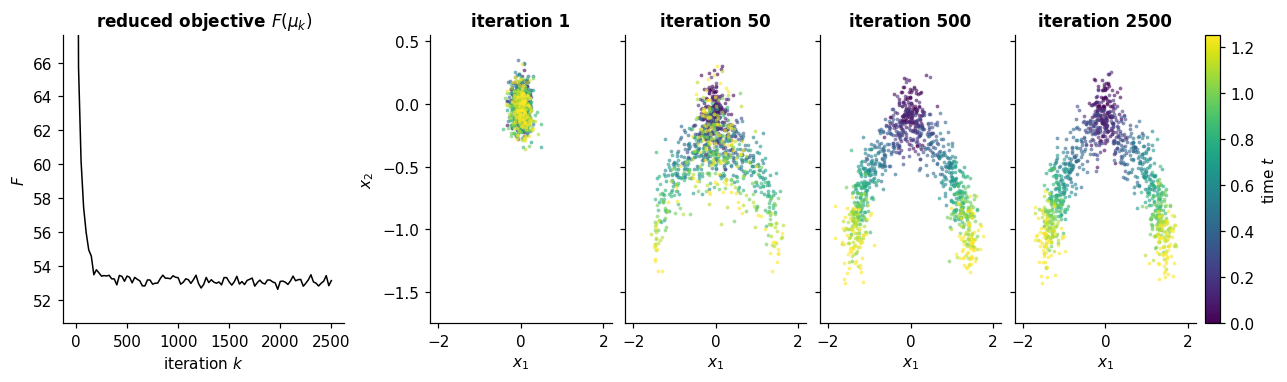

In [12]:
fig = plt.figure(figsize=(15, 3.4))
gs = fig.add_gridspec(1, 6, width_ratios=[1.3, 0.25, 1, 1, 1, 1], wspace=0.08)
ax = fig.add_subplot(gs[0])
ax.plot(trace[:, 0], trace[:, 1], color="k", lw=1)
ax.set(title="reduced objective $F(\\mu_k)$", xlabel="iteration $k$", ylabel="$F$")
ax.set_ylim(trace[2:, 1].min() - 2, trace[2:, 1].min() + 15)
for j, k in enumerate([1, 50, 500, 2500]):
    a = fig.add_subplot(gs[2 + j])
    sm = scatter_snapshots(a, snaps[k], TS, s=6, alpha=0.6)
    style_xy(a, f"iteration {k}")
    if j: a.set(ylabel=None, yticklabels=[])
fig.colorbar(sm, ax=fig.axes[-4:], label="time $t$", pad=0.01)
plt.show()

This is the analogue of the paper's **Figure 2**. Starting from ten identical Gaussian blobs, the particle clouds spread out under the data-fitting forces while the Schrödinger bridges keep consecutive time points coherent. Within a few hundred iterations the reconstruction settles into the bifurcating "V". Afterwards $F$ only fluctuates, reflecting the finite-particle noise of a Langevin sampler at temperature $\tau$.

The animation below (saved to `assets/mfl_dynamics.gif`) shows the whole optimisation trajectory.

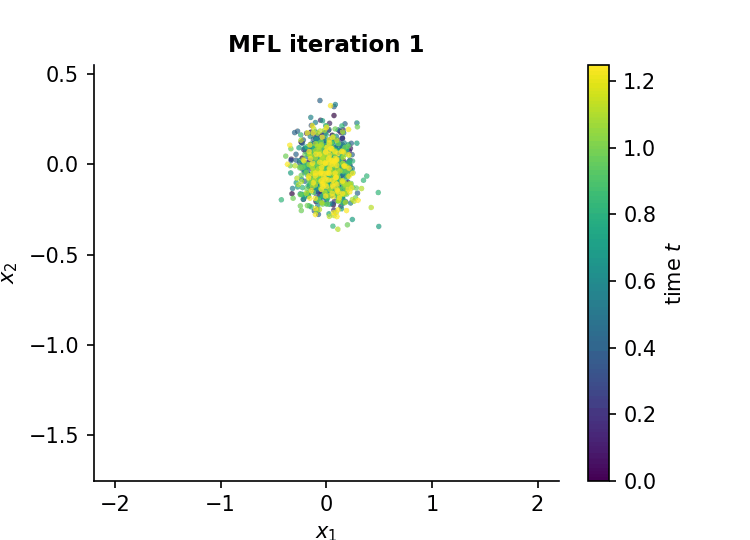

In [13]:
from IPython.display import Image, display

keys = sorted(snaps)
fig, ax = plt.subplots(figsize=(5, 3.6))
norm = mpl.colors.Normalize(TS.min(), TS.max())
colors = np.repeat(plt.get_cmap(TIME_CMAP)(norm(TS)), mfl.m, axis=0)
sc = ax.scatter(*snaps[keys[0]][:, :, :2].reshape(-1, 2).T, s=7, c=colors, alpha=0.7, lw=0)
style_xy(ax)
fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=TIME_CMAP), ax=ax, label="time $t$")
title = ax.set_title("")
def update(f):
    sc.set_offsets(snaps[keys[f]][:, :, :2].reshape(-1, 2))
    title.set_text(f"MFL iteration {keys[f]}")
    return sc, title
frames = list(range(0, 21)) + list(range(22, len(keys), 4))   # dense early, sparse later
anim = animation.FuncAnimation(fig, update, frames=frames, interval=120)
anim.save(ASSETS / "mfl_dynamics.gif", writer=animation.PillowWriter(fps=8))
plt.close(fig)
display(Image(filename=str(ASSETS / "mfl_dynamics.gif")))

<a id="7"></a>
## 7. From marginals back to trajectories

Thanks to the Representer Theorem, the optimised marginals plus their Schrödinger couplings define a full law on paths $R^\star$. We sample trajectories by chaining the transition kernels $\gamma_{i,i+1}(\cdot|x_i)$ and drawing **Brownian bridges** between consecutive knots. The plot compares the inferred paths with the hidden ground-truth paths.

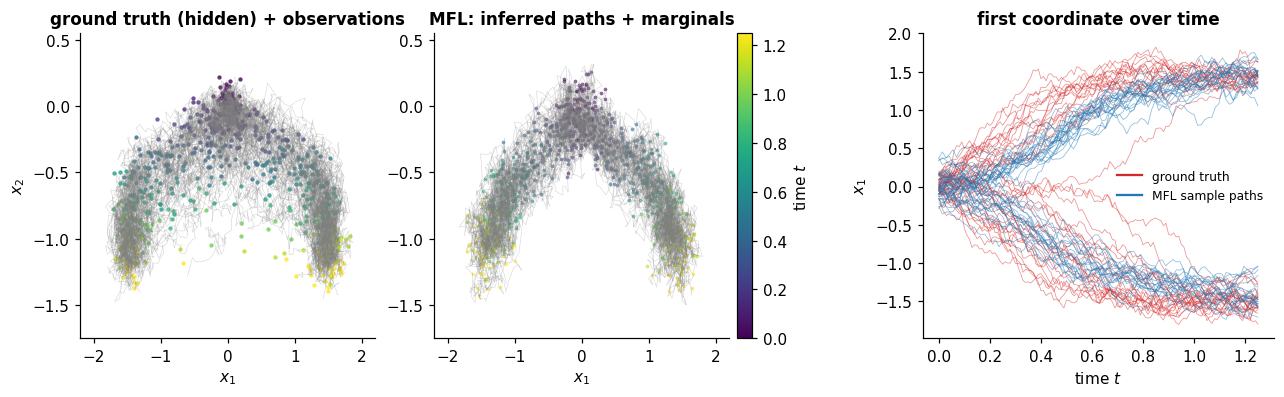

paths ending in the right branch: inferred 0.50, ground truth 0.49


In [14]:
tt, paths = mfl.sample_paths(150, n_sub=10, seed=1)
t_gt = np.arange(gt_paths.shape[0]) * 0.01

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].plot(gt_paths[:, :, 0], gt_paths[:, :, 1], color="grey", lw=0.4, alpha=0.3)
scatter_snapshots(axes[0], obs64, TS, s=8)
style_xy(axes[0], "ground truth (hidden) + observations")
axes[1].plot(paths[:, :, 0], paths[:, :, 1], color="grey", lw=0.4, alpha=0.3)
sm = scatter_snapshots(axes[1], mfl.X, TS, s=6, alpha=0.6)
style_xy(axes[1], "MFL: inferred paths + marginals")
axes[1].set(ylabel=None)
axes[2].plot(t_gt, gt_paths[:, :40, 0], color="C3", lw=0.5, alpha=0.5)
axes[2].plot(tt, paths[:, :40, 0], color="C0", lw=0.5, alpha=0.5)
axes[2].plot([], [], color="C3", label="ground truth"); axes[2].plot([], [], color="C0", label="MFL sample paths")
axes[2].set(title="first coordinate over time", xlabel="time $t$", ylabel="$x_1$"); axes[2].legend(fontsize=8, frameon=False)
fig.colorbar(sm, ax=axes[:2], label="time $t$", pad=0.01)
plt.show()

frac = lambda P: (P[-1, :, 0] > 0).mean()
_, many = mfl.sample_paths(4000, n_sub=1, seed=2)
print(f"paths ending in the right branch: inferred {frac(many):.2f}, ground truth {(truth[-1, :, 0] > 0).mean():.2f}")

The inferred trajectories commit to a branch gradually and keep it, as the true process does. This information about *who goes where* is not contained in any single snapshot. It comes from combining the data with the entropic prior.

<a id="8"></a>
## 8. Grid-free inference: robustness to few samples

The first algorithm for this estimator, **Global Waddington-OT (gWOT)** by Lavenant et al., discretises space. Each reconstructed marginal is a *weight vector on a fixed support*, the union of all observed points, which turns the problem into a finite-dimensional convex programme. The price is that the reconstruction can only put mass where some cell was observed. When intermediate time points contain very few samples, that support is a poor description of the true marginals and the reconstruction inherits its gaps.

MFL is **grid-free**: its particles move continuously in $\mathcal X$. Information can flow from well-sampled time points to poorly sampled ones through the Schrödinger bridges, and the particles fill the gaps wherever the Brownian prior and the data agree. Following Sec. 4.1, we keep 64 samples at the first and last time points and vary the number $N$ of samples at the 8 intermediate time points.

*Note.* The paper compares against the authors' gWOT implementation ([github.com/zsteve/gWOT](https://github.com/zsteve/gWOT)). This notebook has no dependencies beyond NumPy/SciPy, so it does not reimplement gWOT. Below we compare MFL against what the data alone provide (the raw snapshots).

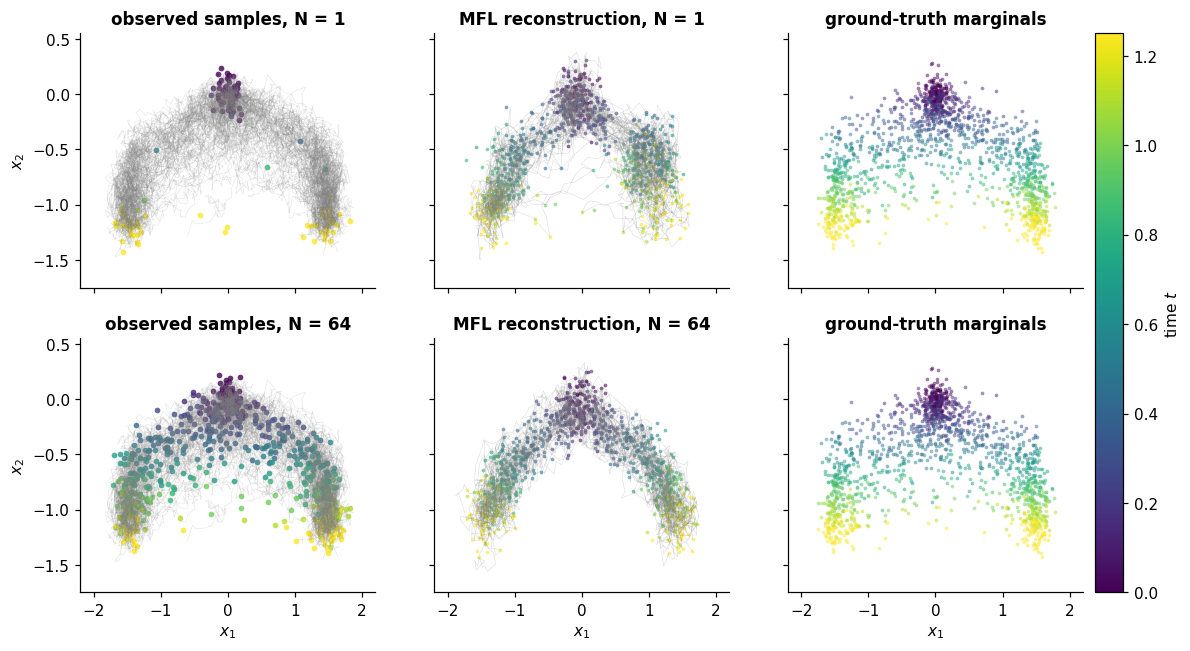

RMS energy distance, N=1:  MFL 0.282 vs raw samples 0.968


In [15]:
def fit_mfl(obs, seed=0, n_iter=2500):
    m_ = MFL(obs, TS, tau=TAU, lam=0.05, sigma=0.5, m=100, seed=seed)
    m_.init_particles(0.1)
    m_.run(n_iter, eta=0.005)
    return m_

obs1 = make_snapshots([64] + [1] * 8 + [64], TS, drift_bifurcation, TAU, rng=11)
mfl1 = fit_mfl(obs1)

fig, axes = plt.subplots(2, 3, figsize=(14, 6.6), sharex=True, sharey=True)
for row, (N, obs, m_) in enumerate([(1, obs1, mfl1), (64, obs64, mfl)]):
    _, p = m_.sample_paths(100, n_sub=6, seed=0)
    axes[row, 0].plot(gt_paths[:, :, 0], gt_paths[:, :, 1], color="grey", lw=0.4, alpha=0.2)
    scatter_snapshots(axes[row, 0], obs, TS, s=14)
    axes[row, 1].plot(p[:, :, 0], p[:, :, 1], color="grey", lw=0.4, alpha=0.25)
    sm = scatter_snapshots(axes[row, 1], m_.X, TS, s=6, alpha=0.6)
    scatter_snapshots(axes[row, 2], truth[:, :150], TS, s=6, alpha=0.5)
    for col, name in enumerate(["observed samples", "MFL reconstruction", "ground-truth marginals"]):
        style_xy(axes[row, col], f"{name}, N = {N}" if col < 2 else name)
        if col: axes[row, col].set_ylabel(None)
        if row == 0: axes[row, col].set_xlabel(None)
fig.colorbar(sm, ax=axes, label="time $t$", pad=0.01)
plt.show()
print(f"RMS energy distance, N=1:  MFL {rms_energy_distance(mfl1.X, truth):.3f} vs raw samples {rms_energy_distance(obs1, truth):.3f}")

With a **single** observed cell at each intermediate time point (top row), the data alone say almost nothing about those marginals. MFL nonetheless reconstructs the bifurcation, with plausible intermediate marginals and trajectories, by propagating information from the well-sampled endpoints through the chain of Schrödinger bridges. The intermediate clouds are blurrier than with $N=64$, but far closer to the truth than the single observed points. This is the analogue of **Figure 1 (left)** of the paper.

To quantify this, we compute the RMS energy distance (Eq. 20) between the reconstruction and a 500-sample ground truth as $N$ varies, over 3 independent datasets. The sweep takes a few minutes, so its results are cached in `results/`.

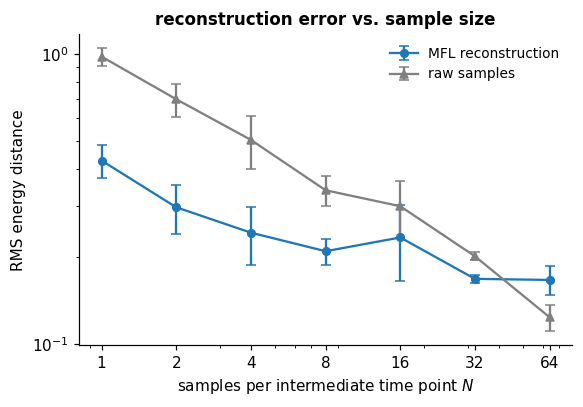

In [16]:
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
NS, SEEDS = [1, 2, 4, 8, 16, 32, 64], [0, 1, 2]
cache = RESULTS / "sweep_energy_distance.npz"

if cache.exists():
    res = dict(np.load(cache))
else:
    res = {k: np.zeros((len(SEEDS), len(NS))) for k in ["mfl", "obs"]}
    t0 = time.time()
    for a, seed in enumerate(SEEDS):
        for b, N in enumerate(NS):
            obs = make_snapshots([64] + [N] * 8 + [64], TS, drift_bifurcation, TAU, rng=1000 * seed + N)
            res["mfl"][a, b] = rms_energy_distance(fit_mfl(obs, seed=seed, n_iter=600).X, truth)
            res["obs"][a, b] = rms_energy_distance(obs, truth)
        print(f"dataset {seed} done ({time.time() - t0:.0f}s)")
    np.savez(cache, **res)

fig, ax = plt.subplots(figsize=(5.4, 3.8))
for key, lab, c, mk in [("mfl", "MFL reconstruction", "C0", "o"), ("obs", "raw samples", "grey", "^")]:
    ax.errorbar(NS, res[key].mean(0), yerr=res[key].std(0), label=lab, color=c, marker=mk, capsize=3, lw=1.5, ms=5)
ax.set(xscale="log", yscale="log", xlabel="samples per intermediate time point $N$", ylabel="RMS energy distance",
       title="reconstruction error vs. sample size")
ax.set_xticks(NS, [str(n) for n in NS]); ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

As $N$ shrinks, the raw snapshots become a poor description of the marginals and their error grows sharply. MFL degrades far more gracefully: pooling information across time through the min-entropy prior makes the estimator **robust to scarce data**. This is the regime in which a fixed-support method is limited by its support (**Figure 1, right** of the paper).

With abundant data the picture flips. MFL's error plateaus around $0.16$, while 64 raw samples per time point eventually do better. The plateau is the **regularisation bias** of the estimator at fixed $(\lambda,\sigma,	au)$: the entropic prior slightly over-diffuses the marginals, as seen at $t=0$ in Section 6. This is the classical bias–variance trade-off. Consistency (Thm. 2.1) requires $\lambda,\sigma	o0$ as data accumulate, so in practice $\lambda$ should be tuned to the sample size, as the paper does with a parameter sweep.

<a id="9"></a>
## 9. Dealing with branching (cell division and death)

Real cell populations do not conserve mass: cells divide and die at state-dependent rates. Suppose we have a prior $g(t,x)$ on the **growth rate**, meaning a cell at $x$ divides with probability $g\,\mathrm dt$ in time $\mathrm dt$. The paper modifies each Schrödinger bridge into an *unbalanced* problem (Eq. 14). With $\rho=+\infty$ (growth known exactly) this amounts to reweighting the marginals that enter the bridge:

$$
\tilde\mu_{t_i}\propto e^{\,g\,(t_{i+1}-t_i)/2}\,\mu_{t_i},\qquad \tilde\mu_{t_{i+1}}\propto e^{-g\,(t_{i+1}-t_i)/2}\,\mu_{t_{i+1}},
$$

so that each source particle is grown forward and each target particle shrunk back by half an interval. Fast-dividing cells at $t_i$ can then "explain" more descendants at $t_{i+1}$. Note that the paper's text writes the opposite signs; the convention above is the one used in the authors' reference implementation, and it is the one consistent with growth.

**Experiment (Sec. 4.2 / App. G.2).** A bistable potential
$\Psi(x)=1.25\,\|x-x^{(0)}\|^2\,\|x-x^{(1)}\|^2+10\sum_{k\ge3}x_k^2$ with wells at $x^{(0)}=(1.4,1.4,0,\dots)$ and $x^{(1)}=(-1.25,-1.25,0,\dots)$, $\tau=1$, and growth rate $g(x)=g_{\max}\,(\tanh(2x_1)+1)/2$. The lower well is closer to the start, so **most individual cells go down**. The upper branch, however, divides faster, so **at late times most observed cells sit in the upper branch**.

We use $g_{\max}=2.5$ instead of the paper's $10$. In our simulation, $g_{\max}=10$ grows the upper branch $\approx e^5$-fold over $[0,0.5]$, so about 95% of sampled cells end up there. The milder rate keeps the observed proportions roughly balanced, as in the paper's Figure 3. A method that ignores growth will confuse "many cells are up there" with "most cells move up there".

In [17]:
A0 = np.zeros(D); A0[:2] = 1.4
A1 = np.zeros(D); A1[:2] = -1.25
TS_B = np.linspace(0, 0.5, 10)

def drift_bistable(t, X):
    da, db = X - A0, X - A1
    g = 2.5 * (da * (db ** 2).sum(1, keepdims=True) + db * (da ** 2).sum(1, keepdims=True))
    g[:, 2:] += 20 * X[:, 2:]
    return g

G_MAX = 2.5
growth_rate = lambda X: G_MAX * (np.tanh(2 * X[..., 0]) + 1) / 2

def simulate_branching(n_pool, ts, n_obs, tau=1.0, dt=1e-3, rng=None):
    # Simulate lineages with weights exp(∫ g dt); a weighted resample at t_i gives a sample of the grown population
    rng = np.random.default_rng(rng)
    X = 0.1 * rng.standard_normal((n_pool, D)); logw = np.zeros(n_pool)
    steps = np.round(ts / dt).astype(int)
    obs, path = [], []
    for k in range(steps[-1] + 1):
        if k in steps:
            p = np.exp(logw - logw.max()); p /= p.sum()
            obs.append(X[rng.choice(n_pool, n_obs, replace=False, p=p)])
        if k % 5 == 0:
            path.append(X[:, 0].copy())
        logw += growth_rate(X) * dt
        X = X - drift_bistable(k * dt, X) * dt + np.sqrt(tau * dt) * rng.standard_normal(X.shape)
    return obs, np.array(path)

obs_b, gt_b = simulate_branching(5000, TS_B, 50, rng=0)
t_b = np.arange(gt_b.shape[0]) * 5e-3
print(f"ground truth: {(gt_b[-1] < 0).mean():.0%} of individual paths end in the lower branch")
print("observed fraction in the lower branch per time point:", np.round([(o[:, 0] < 0).mean() for o in obs_b], 2))

ground truth: 70% of individual paths end in the lower branch
observed fraction in the lower branch per time point: [0.66 0.74 0.68 0.66 0.56 0.52 0.64 0.54 0.42 0.42]


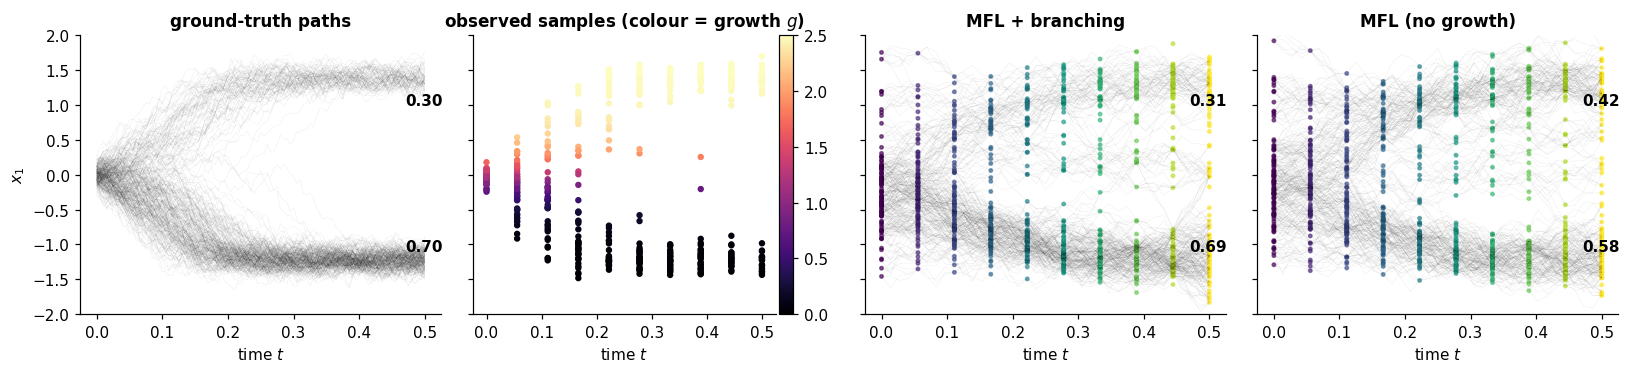

In [18]:
fits = {}
for name, g in [("MFL + branching", growth_rate), ("MFL (no growth)", None)]:
    mb = MFL(obs_b, TS_B, tau=1.0, lam=0.025, sigma=0.5, m=100, growth=g, seed=0)
    mb.init_particles(0.1)
    mb.run(1500, eta=0.0025)
    fits[name] = mb

fig, axes = plt.subplots(1, 4, figsize=(15, 3.5), sharey=True)
annot = lambda ax, frac, x=0.47: (ax.text(x, 1.0, f"{1 - frac:.2f}", fontsize=10, weight="bold"),
                                  ax.text(x, -1.1, f"{frac:.2f}", fontsize=10, weight="bold"))
axes[0].plot(t_b, gt_b[:, :300], color="k", lw=0.3, alpha=0.08)
annot(axes[0], (gt_b[-1] < 0).mean()); axes[0].set(title="ground-truth paths", ylabel="$x_1$")
gcol = axes[1].scatter(np.repeat(TS_B, 50), np.concatenate(obs_b)[:, 0], c=growth_rate(np.concatenate(obs_b)),
                       cmap="magma", s=10, vmin=0, vmax=G_MAX)
axes[1].set(title="observed samples (colour = growth $g$)")
fig.colorbar(gcol, ax=axes[1], pad=0.01)
for ax, (name, mb) in zip(axes[2:], fits.items()):
    tt, P = mb.sample_paths(2000, n_sub=4, seed=0)
    ax.plot(tt, P[:, :300, 0], color="k", lw=0.3, alpha=0.08)
    ax.scatter(np.repeat(TS_B, mb.m), mb.X[:, :, 0].ravel(), c=np.repeat(TS_B, mb.m), cmap=TIME_CMAP, s=5, alpha=0.6)
    annot(ax, (P[-1, :, 0] < 0).mean()); ax.set(title=name)
for ax in axes: ax.set(xlabel="time $t$", ylim=(-2, 2))
plt.tight_layout(); plt.show()

Numbers in bold give the fraction of inferred trajectories ending in the upper and lower branch (cf. **Figure 3** of the paper).

* **Without growth**, the model must conserve mass, so the fraction of particles in each branch is the same at every time. The best it can do is to match the *average* observed proportion, and it explains the late excess of upper-branch cells by cells **migrating** upwards. Proliferation is mistaken for migration, and too many lineages are sent up.
* **With the growth correction**, the reweighted bridges let the upper branch gain mass by division. The inferred lineages go down in close to the true proportion, while the reconstructed marginals still follow the observed shift towards the upper branch.

<a id="10"></a>
## 10. Simulated annealing (App. F)

Theorem 3.3 has a rate $e^{-Cs}$ with $C=\beta e^{-\alpha/\epsilon}$, so convergence can be slow when particles start far from the data. A practical remedy is **simulated annealing**: start with a higher temperature and decay it geometrically to its target. The paper anneals $(\tau,\sigma^2,\eta)$ jointly, starting from $5\times$ their target values, during the first 500 iterations. Here we start both runs from a poorly matched initialisation, $\mathcal N(0,I)$ in all 10 dimensions, and track the distance to the ground truth.

In [19]:
curves = {}
for name, kw in [("MFL", {}), ("MFL + annealing $(\\tau,\\sigma,\\eta)$", dict(anneal_iters=500, anneal_factor=5.0))]:
    ma = MFL(obs64, TS, tau=TAU, lam=0.05, sigma=0.5, m=100, seed=0)
    ma.init_particles(1.0)
    sn, tr = ma.run(1000, eta=0.005, record_every=25, track_every=25, **kw)
    curves[name] = (sn, tr, [(k, rms_energy_distance(x, truth)) for k, x in sorted(sn.items())])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for name, (sn, tr, ed) in curves.items():
    axes[0].plot(tr[:, 0], tr[:, 1], label=name)
    axes[1].plot(*np.array(ed).T, label=name)
axes[0].set(title="reduced objective $F$", xlabel="iteration", ylim=(trace[:, 1].min() - 3, trace[:, 1].min() + 40))
axes[1].set(title="RMS energy distance to ground truth", xlabel="iteration", yscale="log")
axes[1].axhline(rms_energy_distance(mfl.X, truth), color="grey", ls=":", label="converged (Sec. 6)")
axes[1].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(14, 5.6), sharex=True, sharey=True)
for r_, (name, (sn, _, _)) in enumerate(curves.items()):
    for c_, k in enumerate([1, 100, 250, 500]):
        scatter_snapshots(axes[r_, c_], sn[k], TS, s=5, alpha=0.6)
        style_xy(axes[r_, c_], f"{name}\niteration {k}" if c_ == 0 else f"iteration {k}")
        axes[r_, c_].set(xlim=(-3, 3), ylim=(-3, 2))
plt.tight_layout(); plt.show()

KeyboardInterrupt: 

At high temperature the particles diffuse quickly and the wide data-fitting kernel pulls even distant particles towards the observations. Once the schedule cools, the particles are already near the right place, so annealing reaches the converged regime in fewer iterations (cf. **Figure 5** of the paper).

<a id="11"></a>
## 11. Interactive playground

*These widgets need a live Jupyter kernel with `ipywidgets` and do not render on GitHub's static viewer. A static example run is shown below them.*

**(a) Explore the optimisation.** Scrub through the MFL iterations from Section 6, choose which measurement times to show, and look at any pair of coordinates (dimensions 3–10 are the confined noise directions).

**(b) Run your own reconstruction** on a 2-D version of the bifurcation (a few seconds per run). Try a tiny $\lambda$ (overfitting the samples), a huge $\lambda$ (the Brownian prior dominates and the clouds blur), or $N=1$.

In [ ]:
try:
    import ipywidgets as widgets
    from ipywidgets import interact, interact_manual

    @interact(iteration=widgets.SelectionSlider(options=keys, value=keys[-1], description="iteration"),
              times=widgets.IntRangeSlider(value=(1, 10), min=1, max=10, description="t index"),
              dims=widgets.Dropdown(options=[(f"x{a+1} vs x{b+1}", (a, b)) for a, b in [(0, 1), (0, 2), (2, 3), (1, 5)]],
                                    description="axes"))
    def explore(iteration, times, dims):
        X = snaps[iteration]; sel = slice(times[0] - 1, times[1])
        a, b = dims
        fig, ax = plt.subplots(figsize=(5.5, 3.8))
        for x, o, t in zip(X[sel], obs64[sel], TS[sel]):
            col = plt.get_cmap(TIME_CMAP)(t / TS.max())
            ax.scatter(x[:, a], x[:, b], s=8, color=col, alpha=0.6, lw=0)
            ax.scatter(o[:, a], o[:, b], s=18, color=col, marker="x", lw=0.8)
        ax.set(xlabel=f"$x_{a+1}$", ylabel=f"$x_{b+1}$", title=f"iteration {iteration}  (dots: MFL, crosses: data)")
        plt.show()
except ImportError:
    print("ipywidgets not installed: `pip install ipywidgets` to enable the playground.")

In [ ]:
def drift_bif_2d(t, X):
    return np.c_[2 * X[:, 0] * (X[:, 0] ** 2 - 2.25), 20 * (X[:, 1] + t)]

truth_2d = simulate(400, TS, drift_bif_2d, TAU, d=2, rng=7)

def playground(lam=0.05, N=8, sigma=0.5, iters=400, seed=0):
    obs = make_snapshots([64] + [N] * 8 + [64], TS, drift_bif_2d, TAU, d=2, rng=seed)
    m_ = MFL(obs, TS, tau=TAU, lam=lam, sigma=sigma, m=80, seed=seed)
    m_.init_particles(0.1); m_.run(iters, eta=min(0.005, 0.1 * lam))
    _, p = m_.sample_paths(80, n_sub=6, seed=seed)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
    scatter_snapshots(axes[0], obs, TS, s=14); style_xy(axes[0], f"observations (N = {N})")
    axes[1].plot(p[:, :, 0], p[:, :, 1], color="grey", lw=0.4, alpha=0.3)
    scatter_snapshots(axes[1], m_.X, TS, s=7, alpha=0.6)
    style_xy(axes[1], f"MFL (λ = {lam}, σ = {sigma}), error = {rms_energy_distance(m_.X, truth_2d):.3f}")
    plt.show()

try:
    interact_manual(playground,
                    lam=widgets.FloatLogSlider(value=0.05, base=10, min=-3, max=1, description="λ"),
                    N=widgets.SelectionSlider(options=[1, 2, 4, 8, 16, 32, 64], value=8, description="N"),
                    sigma=widgets.FloatSlider(value=0.5, min=0.1, max=1.5, step=0.1, description="σ"),
                    iters=widgets.IntSlider(value=400, min=100, max=1500, step=100, description="iterations"),
                    seed=widgets.IntSlider(value=0, min=0, max=20, description="data seed"))
except NameError:
    pass

# static example run with the default settings
playground(lam=0.05, N=8, iters=600)

<a id="12"></a>
## 12. Summary

| | |
|---|---|
| **Problem** | Recover the law of a stochastic process on paths from snapshots of its marginals, without ever observing an individual twice. |
| **Estimator** | Min-entropy estimator (Lavenant et al.): data fit + $\tau\,H(R\,|\,W^\tau)$. Consistent, but posed on an infinite-dimensional path space. |
| **Key reduction** | Representer theorem: optimise $T$ marginals coupled by Schrödinger bridges; the objective is *smooth + entropy*. |
| **Algorithm** | Mean-Field Langevin: $T$ interacting particle clouds doing noisy gradient descent, with forces from the data and from their neighbours in time (via Sinkhorn). |
| **Guarantees** | Exponential convergence to the global minimiser in the mean-field limit (Thm. 3.3), so the inference method has end-to-end guarantees. |
| **Practice** | Grid-free and robust to scarce data, even one sample per time point (Sec. 8); extends heuristically to branching populations (Sec. 9); benefits from simulated annealing (Sec. 10). |

**Not reproduced here.** Section 4.3 of the paper applies MFL to the iPSC reprogramming scRNA-seq dataset of Schiebinger et al. (2019). The same `MFL` class applies after projecting the expression data to 10 principal components and rescaling costs as described in App. H, but the dataset (~60k cells) is not bundled with this notebook.

### References

1. L. Chizat, S. Zhang, M. Heitz, G. Schiebinger. *Trajectory Inference via Mean-field Langevin in Path Space.* NeurIPS 2022. [arXiv:2205.07146](https://arxiv.org/abs/2205.07146). Reference code: [github.com/zsteve/mfl](https://github.com/zsteve/mfl)
2. H. Lavenant, S. Zhang, Y.-H. Kim, G. Schiebinger. *Towards a mathematical theory of trajectory inference.* arXiv:2102.09204, 2021.
3. G. Schiebinger et al. *Optimal-transport analysis of single-cell gene expression identifies developmental trajectories in reprogramming.* Cell, 2019.
4. K. Hu, Z. Ren, D. Šiška, Ł. Szpruch. *Mean-field Langevin dynamics and energy landscape of neural networks.* 2021. A. Nitanda, D. Wu, T. Suzuki. *Convex analysis of the mean field Langevin dynamics.* AISTATS 2022. L. Chizat. *Mean-field Langevin dynamics: exponential convergence and annealing.* TMLR 2022.
5. G. Peyré, M. Cuturi. *Computational Optimal Transport.* Foundations and Trends in ML, 2019.
6. M. Nutz. *Introduction to Entropic Optimal Transport.* Lecture notes, 2021.